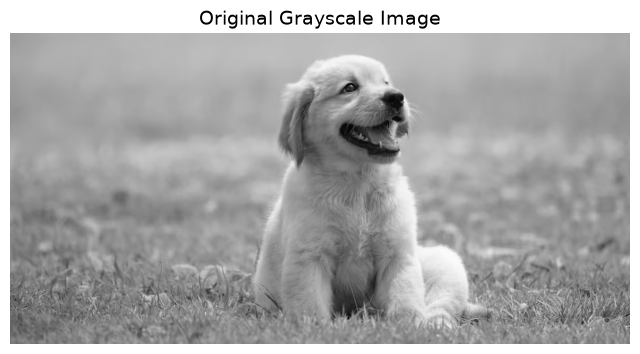

Height : 602
Width  : 1200


In [8]:
import cv2
import matplotlib.pyplot as plt
import random
import numpy as np
img = cv2.imread("../Data/Dog.jpg")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(8,6))
plt.imshow(gray, cmap="gray")
plt.title("Original Grayscale Image", fontsize=14)
plt.axis("off")
plt.show()

height, width = gray.shape
print("Height :", height)
print("Width  :", width)


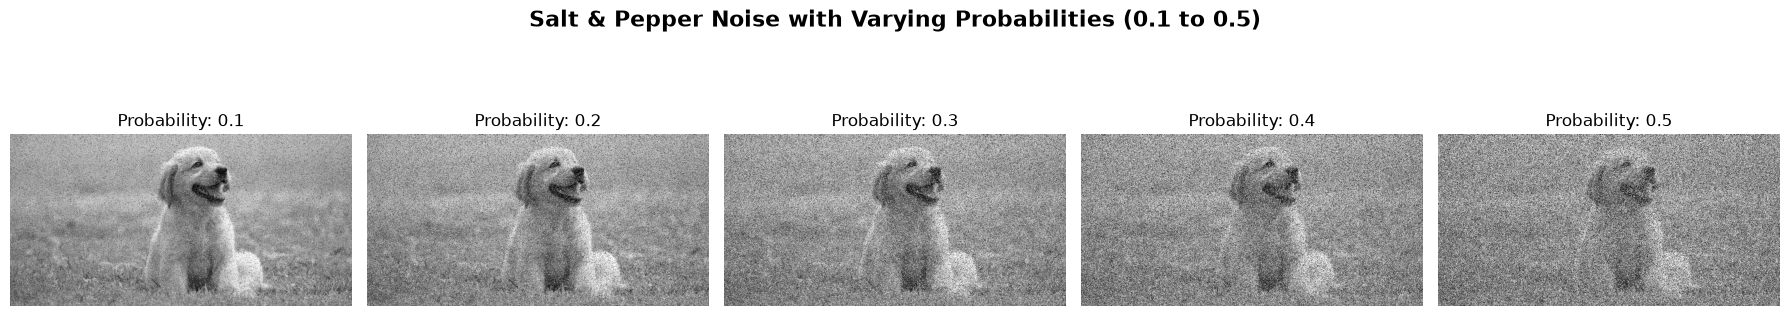

In [19]:
def add_salt_pepper_noise(image: np.ndarray, probability=0.3):
  noisy = image.copy()
  for row in range(0, image.shape[0]):
    for column in range(0, image.shape[1]):
      prob = np.random.rand()
      if(prob < probability/2):
        noisy[row, column] = 0
      elif (prob > 1 - probability/2):
        noisy[row, column]=255
  return noisy

# Vectorized wrapper for efficient multi-probability plotting
def add_salt_pepper_noise_vectorized(image: np.ndarray, probability=0.3):
  noisy = image.copy()
  random = np.random.rand(*image.shape)
  noisy[random < probability / 2] = 0
  noisy[random > 1 - probability / 2] = 255
  return noisy

probabilities = [0.1, 0.2, 0.3, 0.4, 0.5]
fig, axes = plt.subplots(1, len(probabilities), figsize=(18, 4))
fig.suptitle("Salt & Pepper Noise with Varying Probabilities (0.1 to 0.5)", fontsize=16, fontweight="bold")

for i, p in enumerate(probabilities):
  noisy_img = add_salt_pepper_noise_vectorized(image=gray, probability=p)
  axes[i].imshow(noisy_img, cmap="gray")
  axes[i].set_title(f"Probability: {p}", fontsize=12)
  axes[i].axis("off")

plt.tight_layout()
plt.show()
noise_prob = 0.4
noisy = add_salt_pepper_noise_vectorized(image=gray, probability=noise_prob)


602 1200
Filtered shape: (602, 1200)


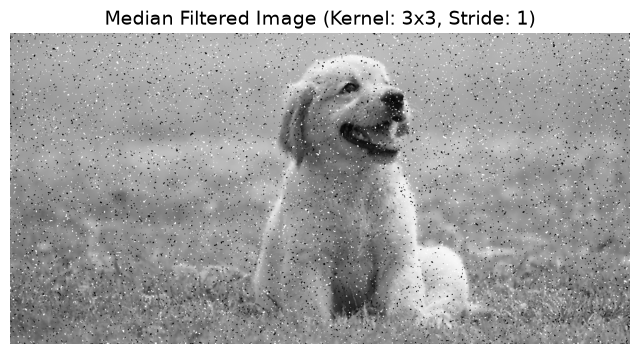

In [22]:
def convolve_with_filter(image: np.ndarray, kernel_size, stride):
  h, w = image.shape
  pad_size = kernel_size // 2
  padded = np.pad(image, pad_size, mode='reflect')
  out_h = int((h + 2*pad_size-kernel_size) / stride +1)
  out_w = int((w + 2*pad_size-kernel_size) / stride +1)
  print(out_h, out_w)
  filtered_image = np.zeros((out_h, out_w))

  for i in range(out_h):
    for j in range(out_w):
      window = padded[i*stride:i*stride+kernel_size, j*stride:j*stride+kernel_size]
      filtered_image[i,j] = np.median(window)
  return filtered_image

filtered = convolve_with_filter(noisy, 3, 1)
print("Filtered shape:", filtered.shape)
plt.figure(figsize=(8,6))
plt.imshow(filtered, cmap="gray")
plt.title("Median Filtered Image (Kernel: 3x3, Stride: 1)", fontsize=14)
plt.axis("off")
plt.show()


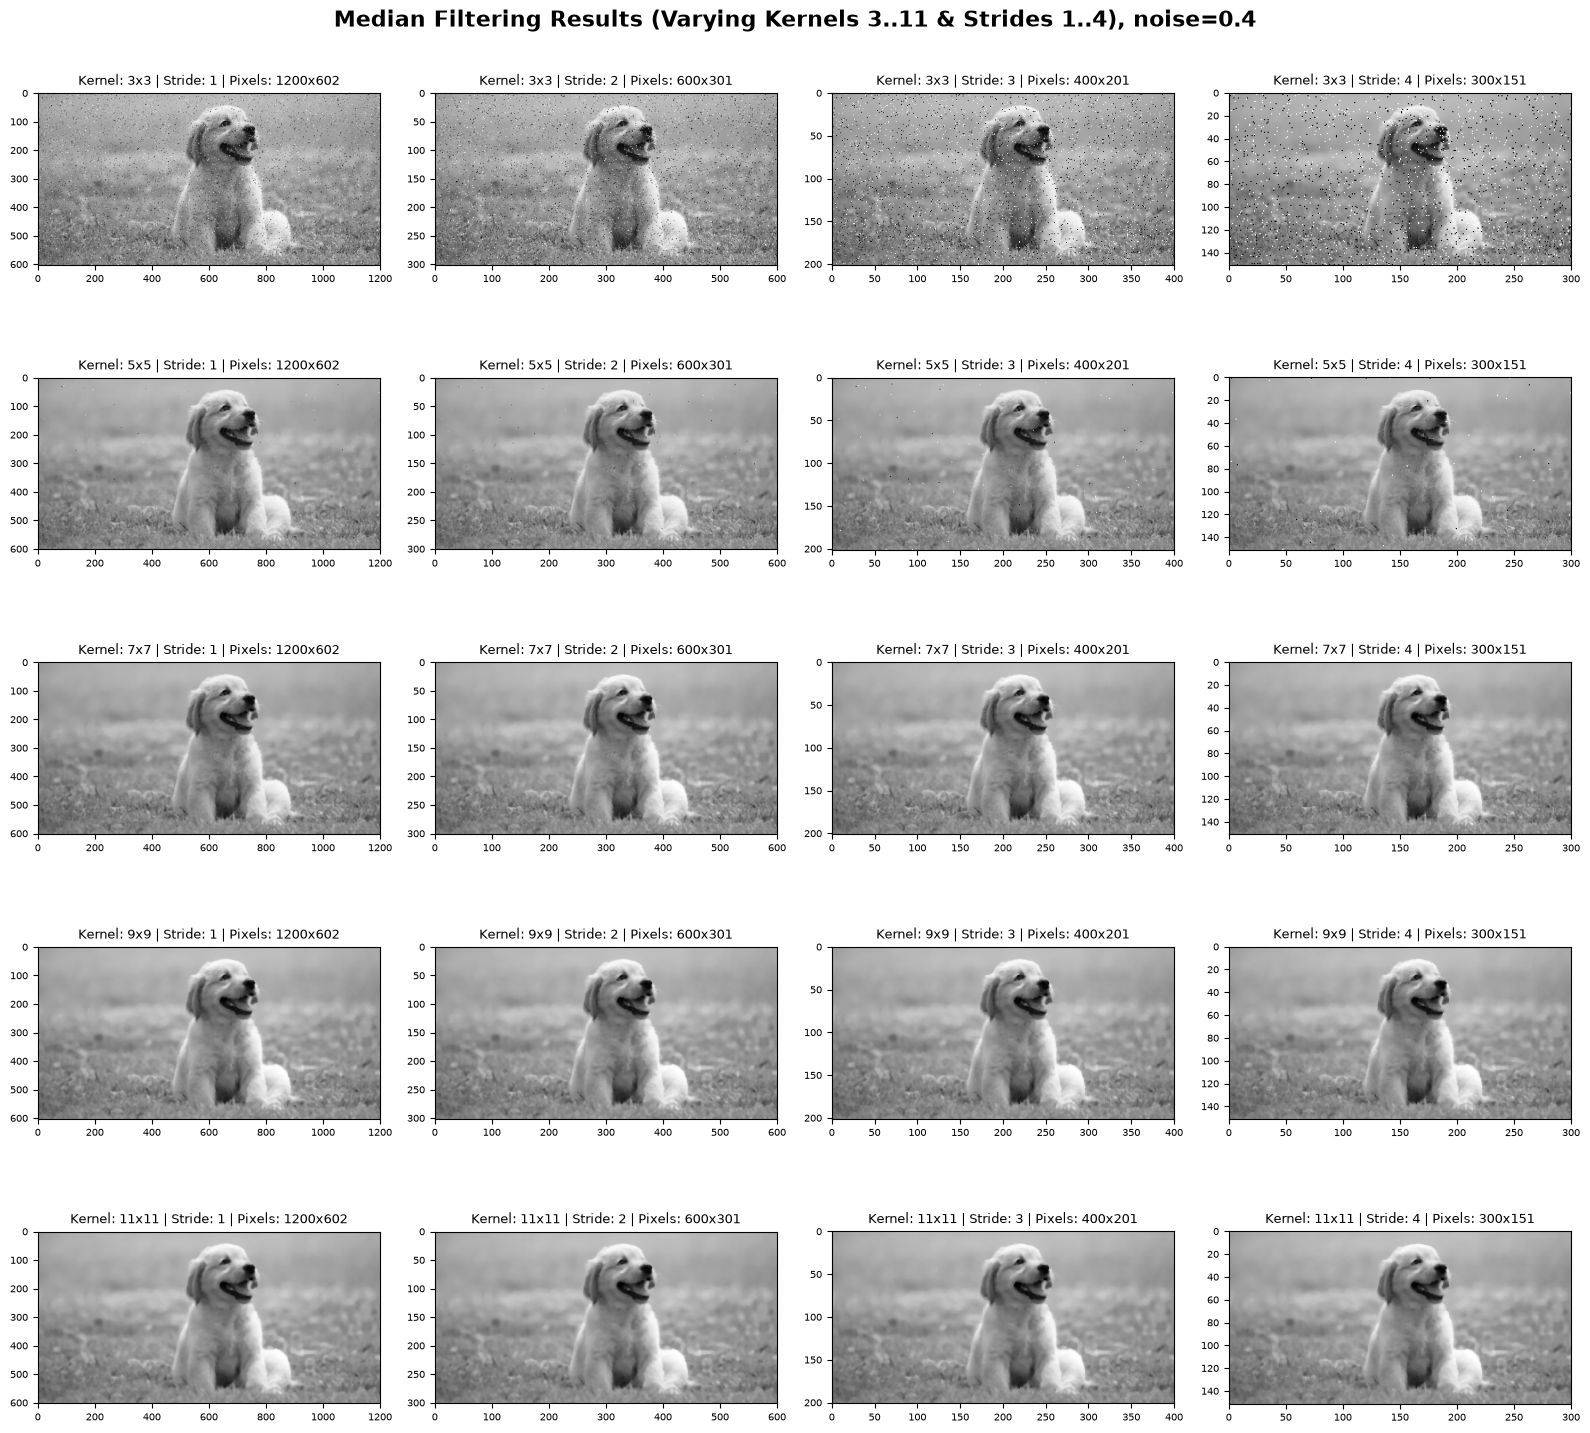

In [25]:
# Median Filter wrapper for expanded kernel sizes and strides
from numpy.lib.stride_tricks import sliding_window_view

def median_filter_wrapper(image: np.ndarray, kernel_size: int, stride: int):
    pad_size = kernel_size // 2
    padded = np.pad(image, pad_size, mode="reflect")
    windows = sliding_window_view(padded, (kernel_size, kernel_size))[::stride, ::stride]
    return np.median(windows, axis=(-2, -1))

kernel_sizes = [3, 5, 7, 9, 11]
strides = [1, 2, 3, 4]

fig, axes = plt.subplots(len(kernel_sizes), len(strides), figsize=(16, 15))
fig.suptitle("Median Filtering Results (Varying Kernels 3..11 & Strides 1..4), noise="+ str(noise_prob), fontsize=16, fontweight="bold")

for r, k in enumerate(kernel_sizes):
    for c, s in enumerate(strides):
        res = median_filter_wrapper(noisy, kernel_size=k, stride=s)
        ax = axes[r, c]
        ax.imshow(res, cmap="gray", extent=[0, res.shape[1], res.shape[0], 0])
        ax.set_title(f"Kernel: {k}x{k} | Stride: {s} | Pixels: {res.shape[1]}x{res.shape[0]}", fontsize=9)
        ax.tick_params(axis="both", which="both", labelsize=7)

plt.tight_layout()
plt.show()


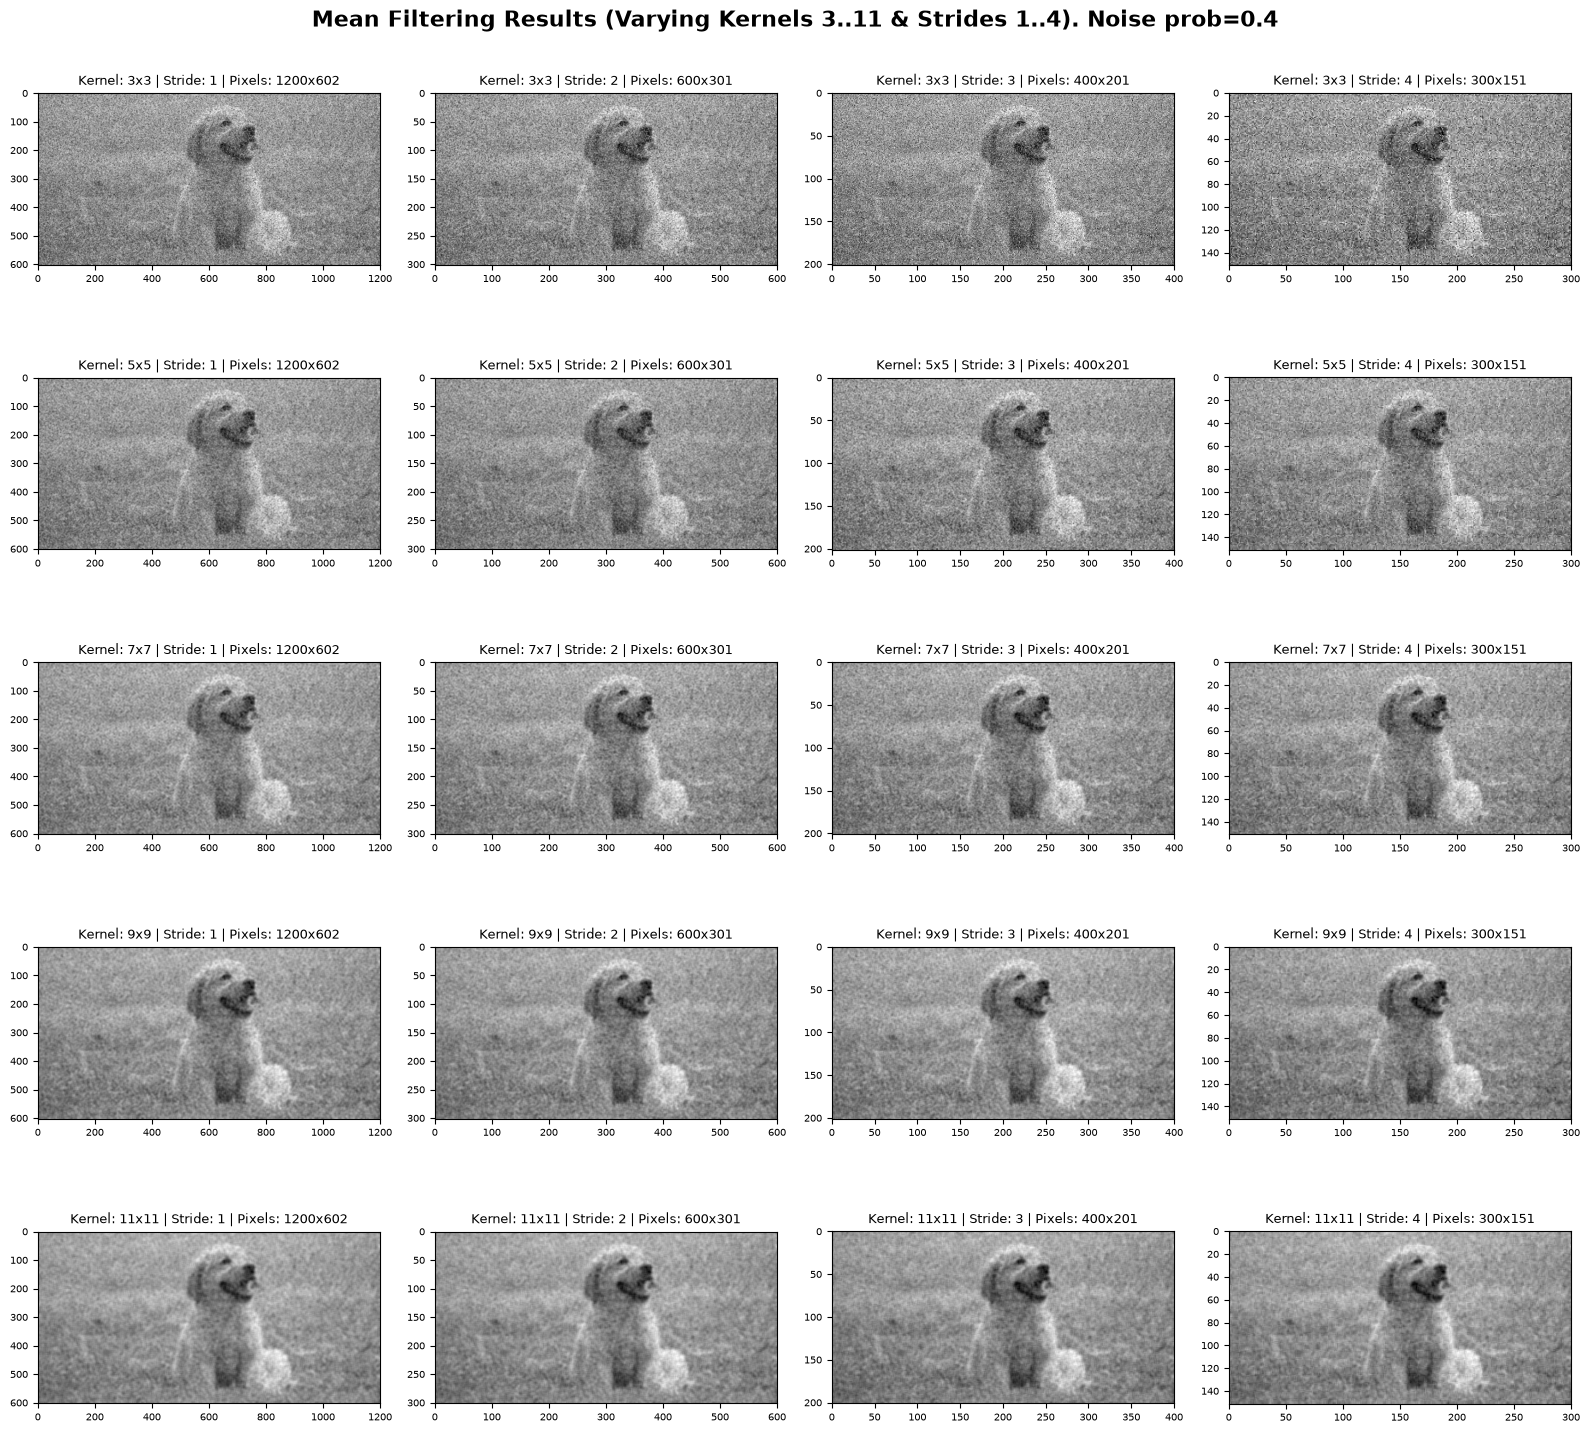

In [27]:
# Mean Filter wrapper for expanded kernel sizes and strides
from numpy.lib.stride_tricks import sliding_window_view

def mean_filter_wrapper(image: np.ndarray, kernel_size: int, stride: int):
    pad_size = kernel_size // 2
    padded = np.pad(image, pad_size, mode="reflect")
    windows = sliding_window_view(padded, (kernel_size, kernel_size))[::stride, ::stride]
    return np.mean(windows, axis=(-2, -1))

kernel_sizes = [3, 5, 7, 9, 11]
strides = [1, 2, 3, 4]

fig, axes = plt.subplots(len(kernel_sizes), len(strides), figsize=(16, 15))
fig.suptitle("Mean Filtering Results (Varying Kernels 3..11 & Strides 1..4). Noise prob="+str(noise_prob), fontsize=16, fontweight="bold")

for r, k in enumerate(kernel_sizes):
    for c, s in enumerate(strides):
        res = mean_filter_wrapper(noisy, kernel_size=k, stride=s)
        ax = axes[r, c]
        ax.imshow(res, cmap="gray", extent=[0, res.shape[1], res.shape[0], 0])
        ax.set_title(f"Kernel: {k}x{k} | Stride: {s} | Pixels: {res.shape[1]}x{res.shape[0]}", fontsize=9)
        ax.tick_params(axis="both", which="both", labelsize=7)

plt.tight_layout()
plt.show()
